# Experiment 14 — Resource-Constrained Decision Reliability (Go/No-Go)
**Purpose:** One tightly scoped model revision. Add explicit travel energy, persistent battery, and a spatial task layout. No new parameter search, no claim of real-flight validation.

**Pre-registered stop rule:** This is the last simulator revision before deciding whether to write a limited simulation paper or stop. A successful run does not automatically establish novelty.

**Model change relative to Experiment 13:** UAVs and tasks have fixed 2-D coordinates; reassignment consumes energy proportional to travel distance. Battery persists across 80 steps. A task is executable only if the UAV has sufficient energy to travel and perform it. The actual and perfect-information policies use the *same* resource model and allocation rule. They differ only in whether the capability score is observed or true. For fair comparison, each policy has its own endogenous battery state, starting from the same world.

**Caveat:** Perfect-information policies may have different battery trajectories. Thus the signed difference is a *policy information effect under the model*, not a pure single-step classification effect. No real UAV energy or flight dynamics are claimed.

In [1]:
import os, json, zipfile, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from IPython.display import display
SEED=20261025; T=80; N=5; K=5
REQ=np.array([78.,67.,55.,43.,32.]); VALUE=np.array([10.,8.,6.,4.,2.])
TASK_XY=np.array([[0.10,.10],[.85,.15],[.80,.85],[.15,.80],[.50,.50]])
BASE_XY=np.array([[.05,.05],[.95,.05],[.95,.95],[.05,.95],[.50,.10]])
BATTERY_INITIAL=120.; ENERGY_PER_DISTANCE=18.; ENERGY_PER_TASK=0.85
# 2D unit square is an abstract mission area, NOT metres; energy units are synthetic.
SCENARIOS={'low_noise':(5.,0.),'high_noise':(22.,0.),'biased_optimism':(12.,12.),'severe_shift':(22.,-20.)}
POLICIES={'continuous':(0.,0.,0.),'no_margin_stable':(0.,1.4,10.),'full':(.25,1.4,10.)}
REPS=30; N_BOOT=1000
OUT='/content/UAV_Resource_Constraint_Audit_Results' if os.path.isdir('/content') else 'UAV_Resource_Constraint_Audit_Results'
os.makedirs(OUT,exist_ok=True)
print('Output directory:',OUT)


Output directory: UAV_Resource_Constraint_Audit_Results


In [2]:
def make_world(seed,noise_sd,bias):
    rng=np.random.default_rng(seed)
    cap=np.empty((T,N));cap[0]=rng.uniform(68,97,N)
    onset=rng.integers(12,52,N); rate=rng.uniform(.35,1.2,N)
    for t in range(1,T):
        cap[t]=np.clip(cap[t-1]+rng.normal(0,.65,N)-(t>=onset)*rate,0,100)
    obs=np.clip(cap+rng.normal(0,noise_sd,cap.shape)+bias,0,100)
    sigma=np.full_like(obs,noise_sd if bias==0 else noise_sd*.5)
    return cap,obs,sigma

def allocate_resource(score,sigma,previous,positions,battery,margin,penalty,bonus):
    distance=np.linalg.norm(positions[:,None,:]-TASK_XY[None,:,:],axis=2)
    energy=ENERGY_PER_DISTANCE*distance+ENERGY_PER_TASK
    eligible=(score[:,None]-margin*sigma[:,None]>=REQ[None,:]) & (battery[:,None]>=energy)
    values=VALUE.copy();values[0]+=bonus
    payoff=np.where(eligible,values[None,:]+.001*score[:,None]-.08*energy,-1e5)
    if penalty:
        for j in range(K):
            if previous[j]>=0: payoff[:,j]-=np.where(np.arange(N)==previous[j],0.,penalty)
    payoff=np.vstack([payoff,np.zeros((K,K))])
    rr,cc=linear_sum_assignment(-payoff)
    chosen=np.full(K,-1,int)
    for i,j in zip(rr,cc):
        if i<N and eligible[i,j]: chosen[j]=i
    return chosen,energy

def trace(world,params,perfect=False):
    cap,obs,sigma=world
    pos=BASE_XY.copy(); battery=np.full(N,BATTERY_INITIAL)
    previous=np.full(K,-1,int)
    utility=unsafe=deferred=critical=switches=0
    spent=0.; stranded=0; executed=0
    for t in range(T):
        score=cap[t] if perfect else obs[t]
        uncert=np.zeros(N) if perfect else sigma[t]
        chosen,energy=allocate_resource(score,uncert,previous,pos,battery,*params)
        assigned=chosen>=0; safe=np.zeros(K,bool)
        if assigned.any():safe[assigned]=cap[t,chosen[assigned]]>=REQ[assigned]
        utility+=VALUE[safe].sum()
        unsafe+=int((assigned&~safe).sum())
        deferred+=int((~assigned).sum()); critical+=int(safe[0])
        switches+=int(((chosen!=previous)&assigned&(previous>=0)).sum())
        for j in np.where(assigned)[0]:
            i=chosen[j]; e=energy[i,j]
            assert battery[i]+1e-8>=e
            battery[i]-=e; spent+=e; pos[i]=TASK_XY[j];executed+=1
        stranded+=int((battery<ENERGY_PER_TASK).sum())
        previous=chosen
    return dict(safe_utility_ratio=float(utility/(T*VALUE.sum())),
        unsafe_per_opportunity=unsafe/(T*K),deferral_rate=deferred/(T*K),
        critical_safe_rate=critical/T,switches=switches,
        energy_spent=spent,mean_final_battery=float(battery.mean()),
        executed=executed,near_empty_uav_steps=stranded)

w=make_world(SEED,12,0)
for params in POLICIES.values():
    a=trace(w,params);b=trace(w,params,perfect=True)
    assert a['safe_utility_ratio']<=1 and b['safe_utility_ratio']<=1
    assert b['unsafe_per_opportunity']==0
print('Sanity checks PASS')


Sanity checks PASS


## Experimental protocol
Same world (latent capability and noisy observations) for every policy, with separate resource trajectories. No parameter tuning. The *matched perfect-information comparator* uses exactly the same policy, task priorities, energy costs and initial conditions. Differences are paired at the world level.

The simulator includes a per-step optimization with resource constraints, but no global dynamic-programming oracle. **Do not label the perfect-information policy a global optimum.**

In [3]:
rows=[]
t0=time.time()
for sidx,(scenario,(sd,bias)) in enumerate(SCENARIOS.items()):
    for rep in range(REPS):
        seed=SEED+1400000+10000*sidx+rep
        world=make_world(seed,sd,bias)
        mae=float(np.abs(world[1]-world[0]).mean())
        signed_bias=float((world[1]-world[0]).mean())
        for name,params in POLICIES.items():
            actual=trace(world,params,False)
            perfect=trace(world,params,True)
            row=dict(scenario=scenario,rep=rep,seed=seed,policy=name,estimation_mae=mae,
                     estimation_bias=signed_bias)
            row.update(actual)
            row.update({'perfect_'+k:v for k,v in perfect.items()})
            row['signed_information_utility_gap']=perfect['safe_utility_ratio']-actual['safe_utility_ratio']
            rows.append(row)
runs=pd.DataFrame(rows)
assert len(runs)==len(SCENARIOS)*REPS*len(POLICIES)
runs.to_csv(os.path.join(OUT,'resource_audit_runs.csv'),index=False)
print('Finished',len(runs),'policy runs in',round(time.time()-t0,1),'seconds')


Finished 360 policy runs in 10.5 seconds


In [4]:
METRICS=['safe_utility_ratio','unsafe_per_opportunity','deferral_rate','critical_safe_rate',
         'switches','energy_spent','mean_final_battery','signed_information_utility_gap']
summary=runs.groupby(['scenario','policy'],as_index=False)[METRICS].agg('mean')
summary.to_csv(os.path.join(OUT,'resource_audit_summary.csv'),index=False)
display(summary.round(4))
rng=np.random.default_rng(SEED+14)
paired=[]
for scenario,g in runs.groupby('scenario'):
    wide=g.set_index(['rep','policy'])
    for left,right in [('full','no_margin_stable'),('full','continuous')]:
        for metric in METRICS:
            a=wide.xs(left,level='policy')[metric].sort_index().to_numpy()
            b=wide.xs(right,level='policy')[metric].sort_index().to_numpy()
            d=a-b
            boot=np.mean(d[rng.integers(0,len(d),size=(N_BOOT,len(d)))],axis=1)
            paired.append(dict(scenario=scenario,comparison=f'{left} minus {right}',metric=metric,
                               mean_difference=float(d.mean()),ci_low=float(np.percentile(boot,2.5)),
                               ci_high=float(np.percentile(boot,97.5))))
paired=pd.DataFrame(paired)
paired.to_csv(os.path.join(OUT,'resource_audit_paired.csv'),index=False)
display(paired[paired.metric.isin(['safe_utility_ratio','unsafe_per_opportunity','signed_information_utility_gap'])].round(4))


,scenario,policy,safe_utility_ratio,unsafe_per_opportunity,deferral_rate,critical_safe_rate,switches,energy_spent,mean_final_battery,signed_information_utility_gap
0,biased_optimism,continuous,0.7154,0.0819,0.1851,0.6300,22.4667,584.2046,3.1591,0.1559
1,biased_optimism,full,0.7088,0.0868,0.1899,0.6067,17.6000,583.8160,3.2368,0.1608
2,biased_optimism,no_margin_stable,0.7236,0.0932,0.1647,0.6208,16.5333,581.7769,3.6446,0.1461
3,high_noise,continuous,0.3592,0.0246,0.6139,0.3137,36.6333,597.4198,0.5160,0.4964
4,high_noise,full,0.3156,0.0242,0.6647,0.2746,28.6000,596.9205,0.6159,0.5380
5,high_noise,no_margin_stable,0.3873,0.0293,0.5878,0.3375,27.2667,597.3144,0.5371,0.4663
6,low_noise,continuous,0.7131,0.0269,0.2191,0.6196,18.9667,537.9457,12.4109,0.1212
7,low_noise,full,0.7111,0.0188,0.2366,0.6171,13.7000,524.7637,15.0473,0.1202
8,low_noise,no_margin_stable,0.7170,0.0280,0.2200,0.6229,12.9667,527.0381,14.5924,0.1143
9,severe_shift,continuous,0.2218,0.0139,0.7483,0.1592,31.1000,596.1786,0.7643,0.6565


,scenario,comparison,metric,mean_difference,ci_low,ci_high
0,biased_optimism,full minus no_margin_stable,safe_utility_ratio,-0.0148,-0.0275,-0.0004
1,biased_optimism,full minus no_margin_stable,unsafe_per_opportunity,-0.0065,-0.0148,0.0023
7,biased_optimism,full minus no_margin_stable,signed_information_utility_gap,0.0148,0.0011,0.0271
8,biased_optimism,full minus continuous,safe_utility_ratio,-0.0066,-0.0190,0.0057
9,biased_optimism,full minus continuous,unsafe_per_opportunity,0.0048,-0.0031,0.0134
15,biased_optimism,full minus continuous,signed_information_utility_gap,0.0049,-0.0075,0.0169
16,high_noise,full minus no_margin_stable,safe_utility_ratio,-0.0717,-0.0944,-0.0484
17,high_noise,full minus no_margin_stable,unsafe_per_opportunity,-0.0051,-0.0138,0.0030
23,high_noise,full minus no_margin_stable,signed_information_utility_gap,0.0717,0.0465,0.0945
24,high_noise,full minus continuous,safe_utility_ratio,-0.0436,-0.0629,-0.0228


,scenario,metric,rho,p_value_descriptive,n_worlds
0,biased_optimism,signed_information_utility_gap,0.2799,0.1341,30
1,biased_optimism,unsafe_per_opportunity,0.2537,0.1761,30
2,biased_optimism,deferral_rate,0.5463,0.0018,30
3,high_noise,signed_information_utility_gap,-0.3057,0.1004,30
4,high_noise,unsafe_per_opportunity,0.4218,0.0203,30
5,high_noise,deferral_rate,0.1057,0.5784,30
6,low_noise,signed_information_utility_gap,0.2210,0.2406,30
7,low_noise,unsafe_per_opportunity,0.2094,0.2666,30
8,low_noise,deferral_rate,0.2457,0.1906,30
9,severe_shift,signed_information_utility_gap,0.0011,0.9953,30


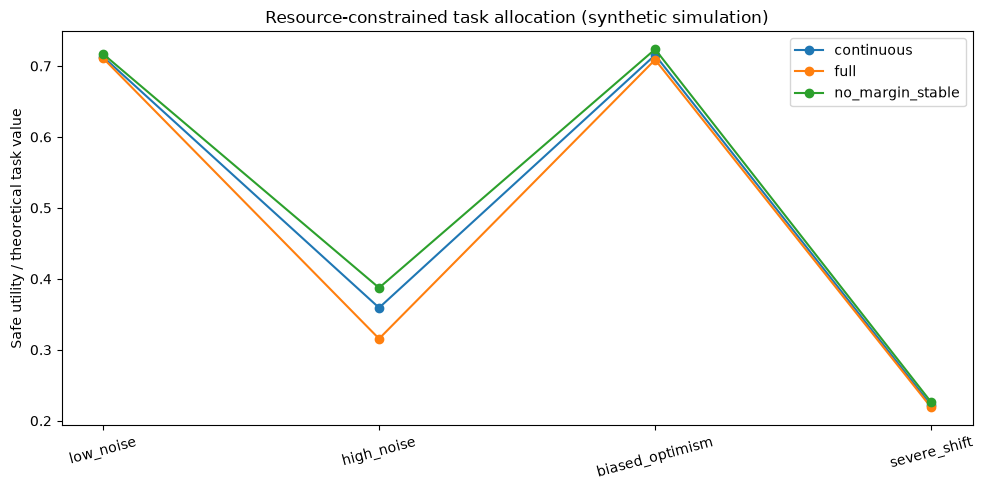

In [5]:
assoc=[]
for scenario,g in runs[runs.policy=='full'].groupby('scenario'):
    for metric in ['signed_information_utility_gap','unsafe_per_opportunity','deferral_rate']:
        r,p=spearmanr(g.estimation_mae,g[metric])
        assoc.append(dict(scenario=scenario,metric=metric,rho=float(r),p_value_descriptive=float(p),n_worlds=len(g)))
assoc=pd.DataFrame(assoc)
assoc.to_csv(os.path.join(OUT,'resource_audit_within_scenario.csv'),index=False)
display(assoc.round(4))
fig,ax=plt.subplots(figsize=(10,5))
for name,g in runs.groupby('policy'):
    x=g.groupby('scenario')['safe_utility_ratio'].mean().reindex(SCENARIOS)
    ax.plot(range(len(x)),x.values,marker='o',label=name)
ax.set_xticks(range(len(SCENARIOS)),list(SCENARIOS),rotation=15)
ax.set_ylabel('Safe utility / theoretical task value')
ax.set_title('Resource-constrained task allocation (synthetic simulation)')
ax.legend();fig.tight_layout()
fig.savefig(os.path.join(OUT,'resource_audit_utility.png'),dpi=160)
plt.show()


In [6]:
# Strict methodological checks and stop/go flags
# This verifies that the resource constraint is active and that the perfect-information
# comparator no longer automatically reaches 100% safe utility.
perfect_cols=runs['perfect_safe_utility_ratio']
active=bool((runs.mean_final_battery<BATTERY_INITIAL-1).all())
nontrivial=bool((perfect_cols<.999999).mean()>.5)
gap_nonzero=bool((runs.signed_information_utility_gap.abs()>1e-9).mean()>.5)
# No 'publication GO' can be inferred automatically; these are only model sanity checks.
verdict={'resource_constraint_active':active,'perfect_information_not_trivial':nontrivial,
         'nonzero_information_gaps_in_majority':gap_nonzero,
         'n_worlds':len(SCENARIOS)*REPS,'n_policy_runs':len(runs),
         'model_limitations':['Synthetic energy units and positions','No flight dynamics',
          'No empirical health-to-capability mapping','No global dynamic oracle',
          'Perfect and imperfect policies follow different endogenous battery paths'],
         'next_step':'Review evidence and stop model development; write with bounded claims or stop project.'}
with open(os.path.join(OUT,'resource_audit_verdict.json'),'w') as f:json.dump(verdict,f,indent=2)
print(json.dumps(verdict,indent=2))
archive='/content/UAV_Resource_Constraint_Audit_Results.zip' if os.path.isdir('/content') else 'UAV_Resource_Constraint_Audit_Results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for name in sorted(os.listdir(OUT)):z.write(os.path.join(OUT,name),arcname=name)
print('ZIP:',archive)
if os.path.isdir('/content'):
    from google.colab import files
    files.download(archive)


{
  "resource_constraint_active": true,
  "perfect_information_not_trivial": true,
  "nonzero_information_gaps_in_majority": true,
  "n_worlds": 120,
  "n_policy_runs": 360,
  "model_limitations": [
    "Synthetic energy units and positions",
    "No flight dynamics",
    "No empirical health-to-capability mapping",
    "No global dynamic oracle",
    "Perfect and imperfect policies follow different endogenous battery paths"
  ],
  "next_step": "Review evidence and stop model development; write with bounded claims or stop project."
}
ZIP: UAV_Resource_Constraint_Audit_Results.zip
